In [1]:
from milliontrees.common.data_loaders import get_train_loader

from milliontrees.datasets.TreePolygons import TreePolygonsDataset
import pandas as pd

In [2]:
import os
import cv2

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

In [3]:
from shapely import wkt
import numpy as np
from PIL import Image, ImageDraw

In [4]:
## polygons
from milliontrees.datasets.TreePolygons import TreePolygonsDataset
dataPolygons = TreePolygonsDataset(root_dir="./data", mini=True,
                            split_scheme="random")

#dataPolygons = TreePolygonsDataset(mini=True)

#training 
trainPolygons = dataPolygons.get_subset("train")
train_loaderPolygons = get_train_loader("standard", trainPolygons, batch_size=2)

In [6]:
dataPolygons.version

'0.11'

In [5]:
from shapely import wkt
import numpy as np
from PIL import Image

In [7]:
# csv loading 
split_path = os.path.join("data", "TreePolygons_v0.11", "random.csv")
split_df = pd.read_csv(split_path)
    
print("Number of rows in split:", len(split_df))

Number of rows in split: 12821


In [8]:
pd.DataFrame(split_df.columns)

,0
0,Unnamed: 0
1,pixelvalue
2,Class
3,Field
4,Shape_Leng
5,Shape_Area
6,NEWSPECIES
7,OneClass
8,Code
9,geometry


In [9]:
split_df.head()

,Unnamed: 0,pixelvalue,Class,Field,Shape_Leng,Shape_Area,NEWSPECIES,OneClass,Code,geometry,...,class_code,taxon_id,Urban_Class_ID,Urban_Class,Street_ID,individual,indiviudal,indiviual,complete,polygon
0,57.0,0.0,AM,0.0,2.738324,0.436864,NaN,tree,ACMIM,"POLYGON ((1080.694737 91.878947, 1056.484211 1...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((1080.694737 91.878947, 1056.484211 1..."
1,53.0,0.0,Acaonc,0.0,2.687688,0.433760,acaitia oncinocarpa,tree,ACONC,"POLYGON ((1455.263158 166.442105, 1422.726316 ...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((1455.263158 166.442105, 1422.726316 ..."
2,54.0,0.0,Acaonc,0.0,2.672413,0.380019,acaitia oncinocarpa,tree,ACONC,"POLYGON ((1323.563158 177.289474, 1294.126316 ...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((1323.563158 177.289474, 1294.126316 ..."
3,250.0,0.0,AM,0.0,0.000000,0.000000,NaN,tree,ACMIM,"POLYGON ((1364.478947 275.221053, 1356.457895 ...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((1364.478947 275.221053, 1356.457895 ..."
4,51.0,0.0,Acaonc,0.0,2.730650,0.501743,acaitia oncinocarpa,tree,ACONC,"POLYGON ((1239.894737 388.010526, 1232.147368 ...",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((1239.894737 388.010526, 1232.147368 ..."


In [10]:
train_rows = split_df[split_df["split"] == "train"]
print("nb lignes train: ",len(train_rows))

nb lignes train:  11434


In [11]:
import random

random_index = random.randint(0, len(train_rows) - 1)
row = train_rows.iloc[random_index]

print("Index choisi:", random_index)
print(row)

Index choisi: 9653
Unnamed: 0                                                      NaN
pixelvalue                                                      NaN
Class                                                           NaN
Field                                                           NaN
Shape_Leng                                                      NaN
Shape_Area                                                      NaN
NEWSPECIES                                                      NaN
OneClass                                                        NaN
Code                                                            NaN
geometry          POLYGON ((130 921, 130 916, 130 912, 128 910, ...
filename                                               rgb_14_1.png
label                                                          tree
Newspecies                                                      NaN
source                                               Li et al. 2023
existing_split               

In [55]:
#first row 

#row = train_rows.iloc[0]

#print("Selected row:")
#print(row)

In [12]:
# filename and geometry
image_filename = row["filename"]
geom_wkt = row["geometry"]  #POLYGON ((x y, x y,...)

In [14]:
# outputs
images_dir = os.path.join("data", "TreePolygons_v0.11", "images")
image_path = os.path.join(images_dir, image_filename)

print("Image path:", image_path)
assert os.path.exists(image_path), f"Image not found: {image_path}"

Image path: data/TreePolygons_v0.11/images/rgb_14_1.png


In [15]:
# load img
img = np.array(Image.open(image_path).convert("RGB"))
# parse polygon with wkt
geom = wkt.loads(geom_wkt) # return a shapely obj ( a polygon)
x, y = geom.exterior.coords.xy
x = np.array(x)
y = np.array(y)


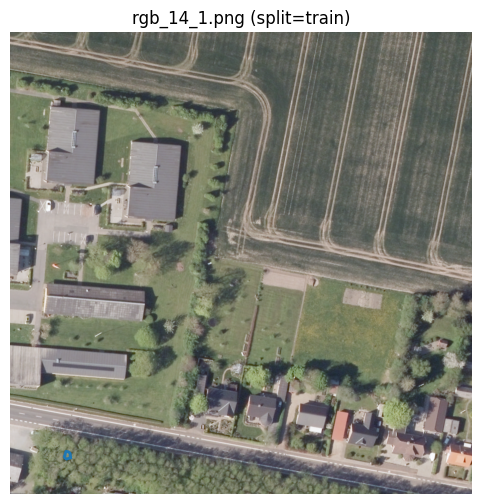

In [17]:
# plot 1 polygon
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)

ax.plot(x, y, linewidth=2)
# ax.fill(x, y, alpha=0.25)

ax.set_title(f"{image_filename} (split={row['split']})")
ax.axis("off")
plt.show()

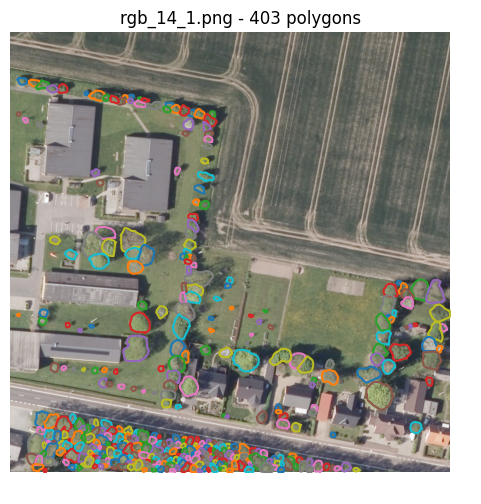

In [19]:
# all polygon detected ?
same = split_df[split_df["filename"] == image_filename]

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img)

for _, r in same.iterrows():
    geom = wkt.loads(r["geometry"])
    x, y = geom.exterior.coords.xy
    ax.plot(x, y, linewidth=1.5)
    #ax.fill(x, y, alpha=0.15)

ax.set_title(f"{image_filename} - {len(same)} polygons")
ax.axis("off")
plt.show()


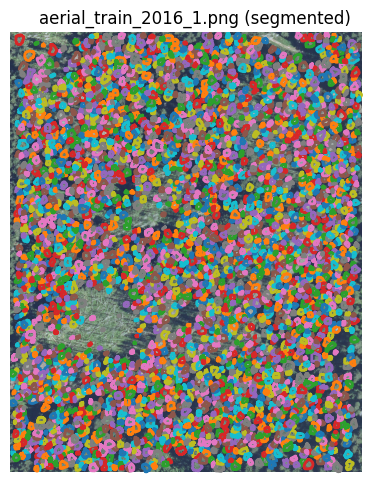

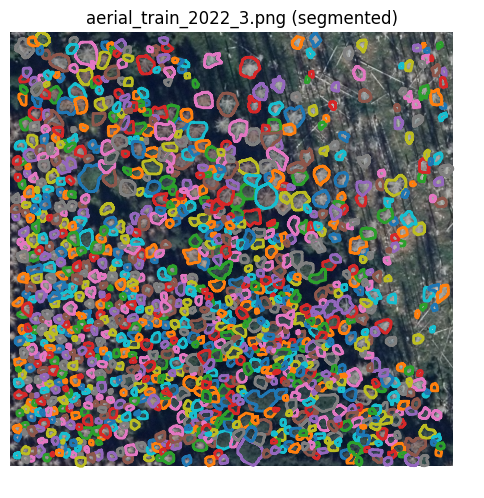

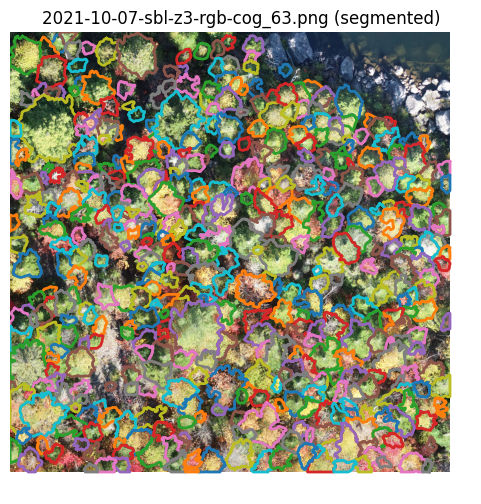

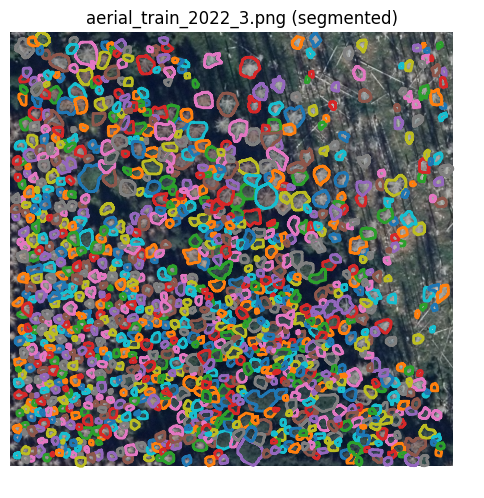

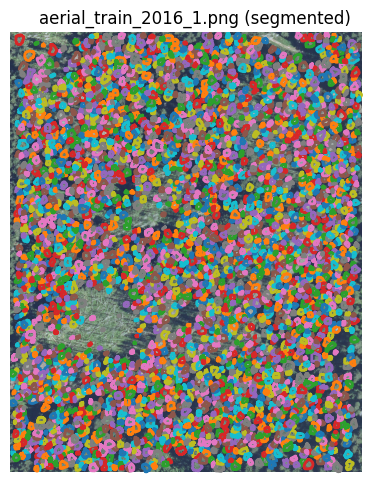

...

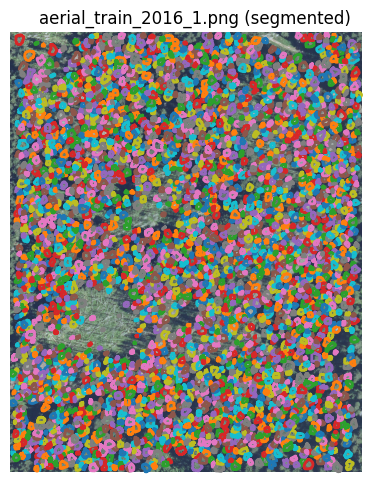

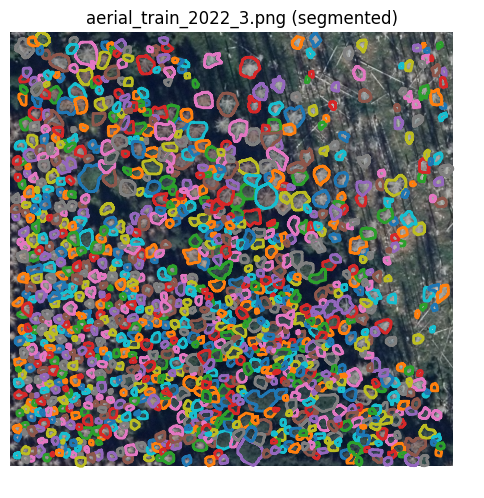

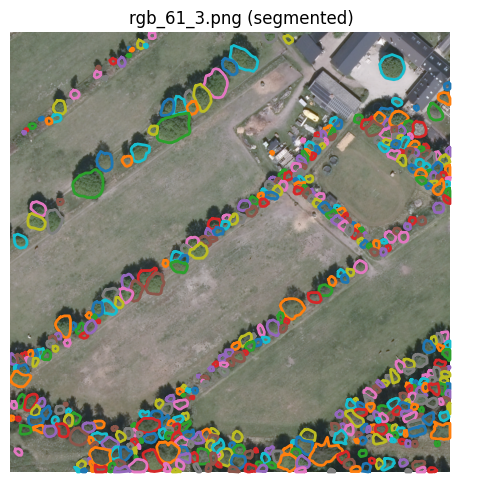

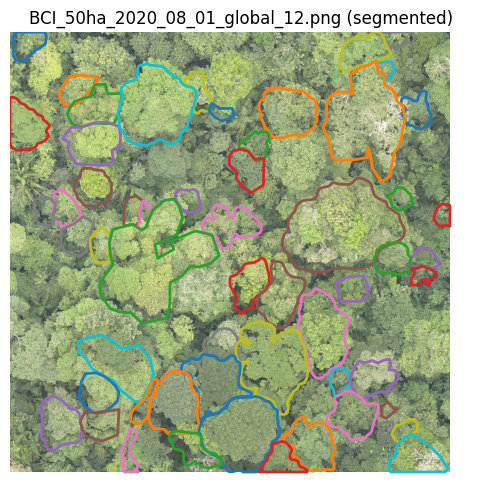

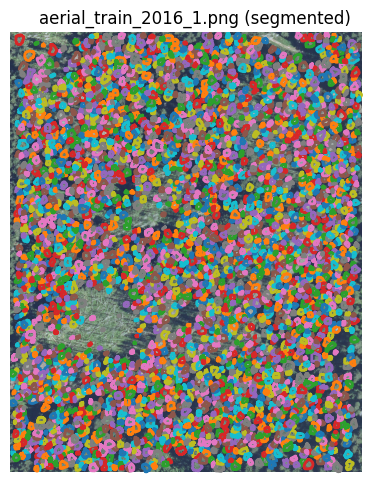

In [28]:
n = 20

for i in range(n):

    random_index = random.randint(0, len(train_rows) - 1)
    row = train_rows.iloc[random_index]
    image_filename = row["filename"]
    same = train_rows[train_rows["filename"] == image_filename]

    image_path = os.path.join(images_dir, image_filename)
    assert os.path.exists(image_path), f"Image not found: {image_path}"
    img = np.array(Image.open(image_path).convert("RGB"))

#    fig, ax = plt.subplots(figsize=(6, 6))
#    ax.imshow(img)
#    ax.set_title(f"{image_filename} (original)")
#    ax.axis("off")
#    plt.show()

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(img)

    for _, r in same.iterrows():
        geom_wkt = r["geometry"]
        geom = wkt.loads(geom_wkt)
        x, y = geom.exterior.coords.xy
        x = np.array(x)
        y = np.array(y)
        ax.plot(x, y, linewidth=2)

    ax.set_title(f"{image_filename} (segmented)")
    ax.axis("off")
    plt.savefig("images/report/eda/polygons_"+image_filename)
    plt.show()


In [93]:
metadata, image, target = trainPolygons[1]
y = target["y"] # annoatations ground truth

print("type:", type(y))

if hasattr(y, "shape"):
    print("shape:", y.shape)

if hasattr(y, "dtype"):
    print("dtype:", y.dtype)

if hasattr(y, "device"):
    print("device:", y.device)

if hasattr(y, "detach"):
    y_np = y.detach().cpu().numpy()
else:
    y_np = np.asarray(y)

print("numpy shape:", y_np.shape)
print("numpy dtype:", y_np.dtype)

print("min:", y_np.min())
print("max:", y_np.max())

print("unique values (first 20):", np.unique(y_np)[:20])


type: <class 'torch.Tensor'>
shape: torch.Size([131, 448, 448])
dtype: torch.uint8
device: cpu
numpy shape: (131, 448, 448)
numpy dtype: uint8
min: 0
max: 255
unique values (first 20): [  0 255]


In [ ]:
#shape: torch.Size([131, 448, 448])
# (nb ab, puis taille img ie 448,488)
# 2 vals : O (ab) ou 255(fond)(si fond ou pas)
# differents mask pour differnets ab de l'image

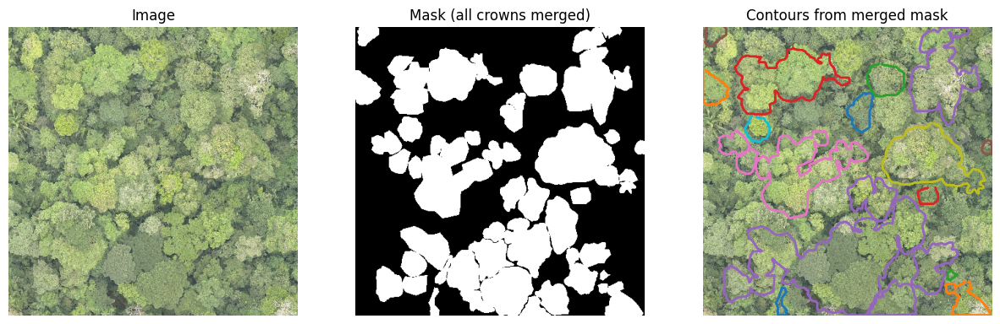

In [92]:
metadata, image, target = trainPolygons[5]
# pytorch : (C, H, W)
# plot : (H, W, C) donc permuter :
img = image.permute(1, 2, 0).numpy()

masks = target["y"].numpy()  #ex :(59,448,448) uint8 0/255
mask_all = masks.max(axis=0).astype(np.uint8)  # (448,448), fusions all masks of an img
contours, _ = cv2.findContours(mask_all, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img)
ax[0].set_title("Image")
ax[0].axis("off")
ax[1].imshow(mask_all, cmap="gray")
ax[1].set_title("Mask (all crowns merged)")
ax[1].axis("off")

ax[2].imshow(img)
ax[2].set_title("Contours from merged mask")
ax[2].axis("off")
for cnt in contours:
    cnt = cnt.squeeze(1)
    if cnt.ndim != 2 or len(cnt) < 3:
        continue
    ax[2].plot(cnt[:, 0], cnt[:, 1], linewidth=2)

plt.show()
